In [1]:
import numpy as np
import fastplotlib as fpl
import matplotlib.pyplot as plt
from tqdm import tqdm
import tifffile
from ipywidgets import HBox, VBox

WGPU: enumerate_adapters() is deprecated, use enumerate_adapters_sync() instead.
WGPU: request_adapter() is deprecated, use request_adapter_sync() instead.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD Radeon Graphics (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 22.3.6
❗ limited,"llvmpipe (LLVM 15.0.6, 256 bits)",CPU,Vulkan,Mesa 22.3.6 (LLVM 15.0.6)
❌,"AMD Radeon Graphics (gfx1103_r1, LLVM 15.0.6, DRM 3.49, 6.1.0-28-amd64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 22.3.6


To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.
To silence this warning, use a fully namespaced name.


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [3]:
from skophys.preprocessing import Vectorizer, UnVectorizer, PercentileFilter

/home/kushal/venvs/fpl/lib/python3.11/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [4]:
%matplotlib inline

In [5]:
path = "./demo_movie_mcorr.tiff"
movie = tifffile.imread(path)

In [6]:
unvec = UnVectorizer(movie.shape[1:])

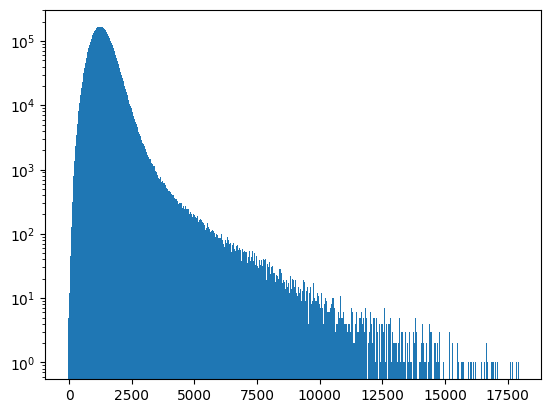

In [7]:
plt.hist(movie.ravel(), bins=1_000)
plt.semilogy()
plt.show()

In [8]:
def mean_psd(y, method='logmexp'):
    """
    Averaging the PSD

    Args:
        y: np.ndarray
             PSD values

        method: string
            method of averaging the noise.
            Choices:
             'mean': Mean
             'median': Median
             'logmexp': Exponential of the mean of the logarithm of PSD (default)

    Returns:
        mp: array
            mean psd
    """

    if method == 'mean':
        mp = np.sqrt(np.mean(y / 2, axis=-1))
    elif method == 'median':
        mp = np.sqrt(np.median(y / 2, axis=-1))
    else:
        mp = np.log((y + 1e-10) / 2)
        mp = np.mean(mp, axis=-1)
        mp = np.exp(mp)
        mp = np.sqrt(mp)

    return mp

def get_noise_fft(Y, noise_range=[0.25, 0.5], noise_method='logmexp', max_num_samples_fft=3072,
                  opencv=True):
    """Estimate the noise level for each pixel by averaging the power spectral density.

    Args:
        Y: np.ndarray
            Input movie data with time in the last axis

        noise_range: np.ndarray [2 x 1] between 0 and 0.5
            Range of frequencies compared to Nyquist rate over which the power spectrum is averaged
            default: [0.25,0.5]

        noise method: string
            method of averaging the noise.
            Choices:
                'mean': Mean
                'median': Median
                'logmexp': Exponential of the mean of the logarithm of PSD (default)

    Returns:
        sn: np.ndarray
            Noise level for each pixel
    """
    T = Y.shape[-1]
    # Y=np.array(Y,dtype=np.float64)

    if T > max_num_samples_fft:
        Y = np.concatenate((Y[..., 1:max_num_samples_fft // 3 + 1],
                            Y[..., int(T // 2 - max_num_samples_fft / 3 / 2)
                                          :int(T // 2 + max_num_samples_fft / 3 / 2)],
                            Y[..., -max_num_samples_fft // 3:]), axis=-1)
        T = np.shape(Y)[-1]

    # we create a map of what is the noise on the FFT space
    ff = np.arange(0, 0.5 + 1. / T, 1. / T)
    ind1 = ff > noise_range[0]
    ind2 = ff <= noise_range[1]
    ind = np.logical_and(ind1, ind2)
    # we compute the mean of the noise spectral density s
    if Y.ndim > 1:
        if opencv:
            import cv2
            try:
                cv2.setNumThreads(0)
            except:
                pass
            psdx_list = []
            for y in Y.reshape(-1, T):
                dft = cv2.dft(y, flags=cv2.DFT_COMPLEX_OUTPUT).squeeze()[
                    :len(ind)][ind]
                psdx_list.append(np.sum(1. / T * dft * dft, 1))
            psdx = np.reshape(psdx_list, Y.shape[:-1] + (-1,))
        else:
            xdft = np.fft.rfft(Y, axis=-1)
            xdft = xdft[..., ind[:xdft.shape[-1]]]
            psdx = 1. / T * abs(xdft)**2
        psdx *= 2
        sn = mean_psd(psdx, method=noise_method)

    else:
        xdft = np.fliplr(np.fft.rfft(Y))
        psdx = 1. / T * (xdft**2)
        psdx[1:] *= 2
        sn = mean_psd(psdx[ind[:psdx.shape[0]]], method=noise_method)

    return sn, psdx

In [9]:
sn, psdx = get_noise_fft(movie.transpose(1, 2, 0))

movie /= sn

In [10]:
iw_movie = fpl.ImageWidget(movie, cmap="viridis")
tfig = fpl.Figure()

raw_trace = tfig[0, 0].add_line(np.zeros(movie.shape[0]))

@iw_movie.managed_graphics[0].add_event_handler("click")
def pixel_clicked(ev):
    col, row = ev.pick_info["index"]
    raw_trace.data[:, 1] =  iw_movie.data[0][:, row, col]
    tfig[0, 0].auto_scale(maintain_aspect=False)

HBox([iw_movie.show(), tfig.show()])

RFBOutputContext()

WGPU: request_device() is deprecated, use request_device_sync() instead.
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

In [12]:
iw_movie.window_funcs = {"t": (np.mean, 11)}

In [13]:
filt_movie = PercentileFilter(window_size=5, quantile=5).transform(movie)

In [14]:
iw_movie.set_data(unvec.transform(filt_movie), reset_indices=False)

In [15]:
from sklearn.preprocessing import RobustScaler

In [16]:
ss = RobustScaler()

In [17]:
Y = ss.fit_transform(filt_movie.T).T

In [18]:
iw_movie.set_data(unvec.transform(Y), reset_indices=False)

In [19]:
Y

array([[-0.89419097, -0.89419097, -0.8748388 , ...,  0.2051251 ,
         1.6246736 , -4.1461906 ],
       [-1.6006716 , -1.6006716 , -1.7303635 , ...,  0.22551222,
         2.132441  , -3.8895519 ],
       [-0.7251243 , -0.8608975 , -0.9109863 , ...,  1.7932593 ,
         3.6691647 , -4.0335784 ],
       ...,
       [-0.7038758 , -0.7038758 , -0.63659984, ...,  2.5688431 ,
         2.999742  , -3.1861932 ],
       [-1.1421993 , -1.1421993 , -1.1421993 , ...,  2.2942994 ,
         2.649461  , -3.1933663 ],
       [-1.0373353 , -1.0373353 , -0.56953984, ...,  0.8750072 ,
         2.248134  , -3.2532547 ]], dtype=float32)

In [20]:
Y.shape

(4800, 2000)

In [21]:
ixs = np.where(np.apply_along_axis(lambda Y_p: np.count_nonzero(Y_p > 3.0) > 10, axis=1, arr=Y))[0]

In [22]:
Y = Y[ixs]

In [23]:
unvec.pixel_indices = ixs

In [24]:
Y.shape

(2049, 2000)

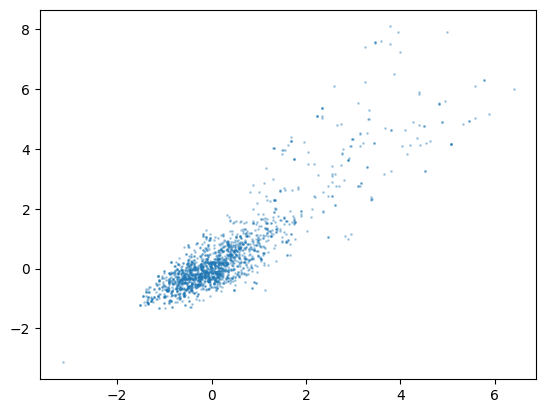

In [25]:
i = 1010
j = 1009

u = Y[i]
v = Y[j]

X = np.column_stack([u, v])

plt.scatter(u, v, s=1, alpha=.3)

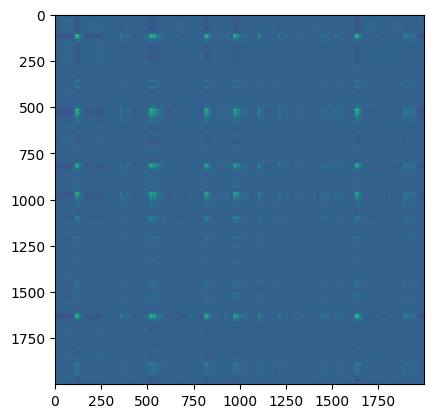

In [26]:
XX_T = X @ X.T
plt.imshow(X @ X.T)

In [27]:
from scipy.sparse.linalg import eigsh, svds

In [28]:
%%time
evals, evecs = eigsh(XX_T, k=1)

CPU times: user 7.02 ms, sys: 0 ns, total: 7.02 ms
Wall time: 6.59 ms


In [29]:
%%timeit
U, S, Vt = np.linalg.svd(X, full_matrices=False)

29.6 μs ± 996 ns per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [30]:
XTX = X.T @ X

In [31]:
XTX.shape

(2, 2)

In [32]:
from scipy.linalg import eigh

In [33]:
evals, evecs = np.linalg.eigh(XTX)
evals, evecs

(array([ 351.3741, 5975.1562], dtype=float32),
 array([[-0.78153795,  0.6238577 ],
        [ 0.6238577 ,  0.78153795]], dtype=float32))

In [34]:
U, S, Vt = np.linalg.svd(X, full_matrices=False)

In [35]:
Vt.shape

(2, 2)

In [36]:
Vt

array([[ 0.62385774,  0.78153795],
       [ 0.78153795, -0.62385774]], dtype=float32)

In [37]:
Vt[0]

array([0.62385774, 0.78153795], dtype=float32)

In [38]:
evecs[0]

array([-0.78153795,  0.6238577 ], dtype=float32)

In [39]:
projections = (X @ Vt[0, :])[:, None] * Vt[0, :]

In [40]:
projections

array([[-0.92181915, -1.1548092 ],
       [-0.90656334, -1.1356975 ],
       [-0.87643653, -1.0979561 ],
       ...,
       [ 0.19391558,  0.24292779],
       [ 0.8225994 ,  1.0305116 ],
       [-2.756664  , -3.4534118 ]], dtype=float32)

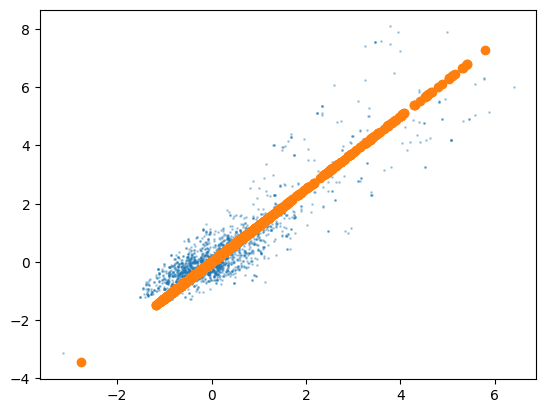

In [41]:
plt.scatter(u, v, s=1, alpha=.3)
plt.scatter(projections[:, 0], projections[:, 1])

In [42]:
from numba import guvectorize, float64, int64, float32, prange, njit
from itertools import product

In [91]:
@njit(parallel=True)
def get_distances(
    i: int,
    Y: np.ndarray,
    projections: np.ndarray,
    dists: np.ndarray,
    low_dists_h: np.ndarray,
    low_dists_v: np.ndarray,
):
    for j in prange(Y.shape[0]):
        u = Y[i]
        v = Y[j]

        high_val_ixs = (u > np.percentile(u, 95)) | (v > np.percentile(v, 95))

        u = u[high_val_ixs]
        v = v[high_val_ixs]

        # u = u**2
        # v = v**2

        # X = np.column_stack([u, v])
        X = np.zeros((u.size, 2))
        X[:, 0] = u
        X[:, 1] = v

        U, S, Vt = np.linalg.svd(X, full_matrices=False)
        v1 = Vt[0, :]

        # projections = (X @ Vt[0, :])[:, None] * Vt[0, :]
        projections_pre = (X @ v1)
        
        projections[j, :u.size, 0] = projections_pre * v1[0]
        projections[j, :u.size, 1] = projections_pre * v1[1]

        orthogonal_distances = np.abs(X - projections[j, :u.size])  # Euclidean distances
        s = 0
        for r in range(X.shape[0]):
            s += np.sqrt(orthogonal_distances[r, 0]**2 + orthogonal_distances[r, 1]**2)

        dists[j] = s

        # hline and vline distances
        hline = np.array([1., 0.])
        vline = np.array([0., 1.])

        projections_h_pre = (X @ hline)
        projections_v_pre = (X @ vline)

        projections_h = np.zeros((u.size, 2))
        projections_h[:, 0] = projections_h_pre * hline[0]
        
        projections_v = np.zeros((u.size, 2))
        projections_v[:, 1] = projections_v_pre * vline[1]

        odists_h = np.abs(X - projections_h)
        low_dists_h[j] = np.count_nonzero(odists_h < orthogonal_distances)

        odists_v = np.abs(X - projections_v)
        low_dists_v[j] = np.count_nonzero(odists_v < orthogonal_distances)

In [92]:
projections = np.zeros((*Y.shape, 2))
output_matrix = np.zeros((Y.shape[0],))
output_h = np.zeros((Y.shape[0],))
output_v = np.zeros((Y.shape[0],))

In [93]:
projections.shape

(2049, 2000, 2)

In [94]:
%%time
get_distances(
    1005,
    Y,
    projections,
    output_matrix,
    output_h,
    output_v
)

CPU times: user 17.2 s, sys: 25 ms, total: 17.3 s
Wall time: 17.2 s


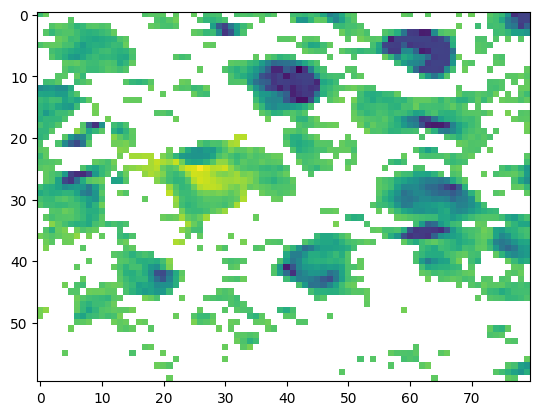

In [95]:
plt.imshow(unvec.transform(output_matrix), cmap="viridis_r")

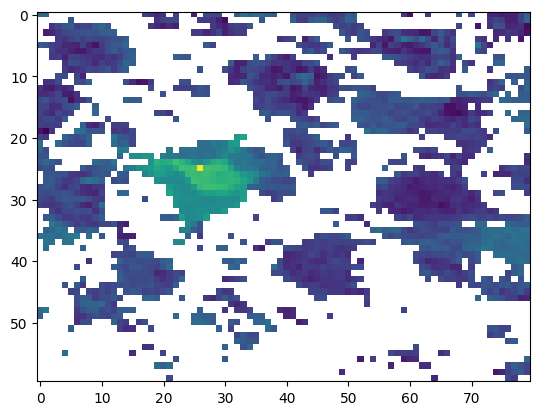

In [88]:
plt.imshow(unvec.transform(output_h), cmap="viridis_r")

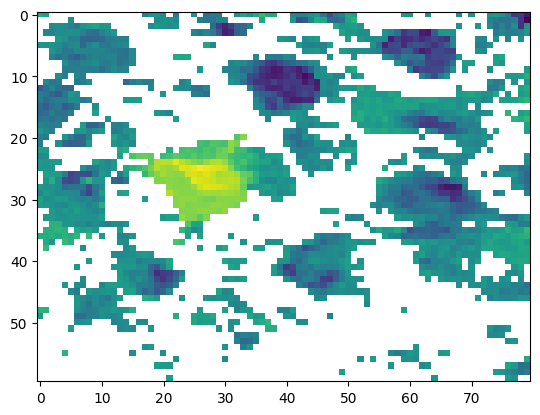

In [49]:
plt.imshow(unvec.transform(output_v), cmap="viridis_r")

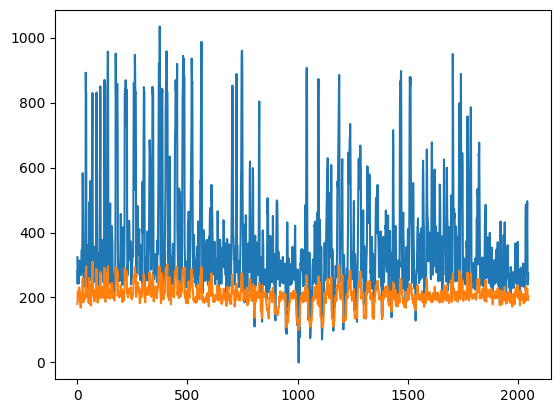

In [50]:
plt.plot(output_matrix)
plt.plot(output_v)

In [51]:
output_v < output_matrix

array([ True,  True,  True, ...,  True,  True,  True])

In [52]:
output_v

array([180., 190., 217., ..., 201., 192., 204.])

In [53]:
output_matrix

array([323.78360939, 242.35305538, 283.72933696, ..., 257.26067259,
       254.3981253 , 273.79181594])

In [54]:
output_matrix

array([323.78360939, 242.35305538, 283.72933696, ..., 257.26067259,
       254.3981253 , 273.79181594])

In [55]:
std = unvec.transform(Y).std(axis=0)
std = np.nan_to_num(std, nan=0)

In [56]:
std

array([[1.140502  , 0.92591405, 0.        , ..., 2.012267  , 2.5870583 ,
        3.1451652 ],
       [0.        , 0.        , 0.        , ..., 1.6951296 , 2.2788587 ,
        2.2837713 ],
       [0.        , 0.        , 0.87352604, ..., 1.5876694 , 2.0429995 ,
        1.7065521 ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.9368028 , 1.1524388 ,
        1.2113141 ],
       [0.        , 0.        , 0.        , ..., 1.1393058 , 1.2369535 ,
        0.9822347 ],
       [0.        , 0.        , 0.        , ..., 0.8366012 , 0.        ,
        0.        ]], dtype=float32)

In [57]:
np.where(unvec.pixel_indices == 2)[0].size

0

In [58]:
iw = fpl.ImageWidget([std, np.zeros(std.shape)], cmap="viridis")

pixel_index_A = 0
projections = np.zeros((*Y.shape, 2))

pixel_A_pt = iw.figure[0, 1].add_scatter(np.array([[0, 0]]), sizes=10, colors="magenta")
pixel_B_pt = iw.figure[0, 1].add_scatter(np.array([[0, 0]]), sizes=10, colors="cyan")

@iw.managed_graphics[0].add_event_handler("double_click")
def update_distance_image(ev):
    global pixel_index_A
    global projections
    
    col, row = ev.pick_info["index"]

    i = np.ravel_multi_index((row, col), unvec.shape)
    subset_indices = np.where(unvec.pixel_indices == i)[0]
    if subset_indices.size < 1:
        return
        
    pixel_index_A = subset_indices.item()

    pixel_A_pt.data[0, 0] = col
    pixel_A_pt.data[0, 1] = row
    
    output_matrix = np.zeros((Y.shape[0],))
    projections = np.zeros((*Y.shape, 2))
    get_distances(
        pixel_index_A,
        Y,
        projections,
        output_matrix
    )

    output_matrix = np.nan_to_num(output_matrix, nan=np.nanmax(output_matrix))
    np.nan_to_num(output_matrix, nan=np.nanmax(output_matrix))
    iw.managed_graphics[1].data = unvec.transform(output_matrix)
    iw.reset_vmin_vmax()


fig_s = fpl.Figure(shape=(1, 2))

scatter_corr = fig_s[0, 0].add_scatter(np.zeros((Y.shape[1], 2)), sizes=4, colors=(1, 0.7, 0, 0.3), alpha=0.3)
scatter_proj = fig_s[0, 0].add_scatter(np.zeros((Y.shape[1], 2)), sizes=4, colors="r", alpha=0.3)
fig_s[0, 0].axes.colors = ("magenta", "cyan", "w")

line_p1 = fig_s[0, 1].add_line(np.arange((Y.shape[1])), colors="magenta", alpha=0.3)
line_p2 = fig_s[0, 1].add_line(np.arange((Y.shape[1])), colors="cyan", alpha=0.3)

selector_time = line_p1.add_linear_selector()

@iw.managed_graphics[1].add_event_handler("double_click")
def update_scatters(ev):
    u = Y[pixel_index_A]

    col, row = ev.pick_info["index"]

    j = np.ravel_multi_index((row, col), unvec.shape)

    subset_indices = np.where(unvec.pixel_indices == j)[0]
    if subset_indices.size < 1:
        return

    j = subset_indices.item()
    
    v = Y[j]

    pixel_B_pt.data[0, 0] = col
    pixel_B_pt.data[0, 1] = row
    
    scatter_corr.data[:, :-1] = np.column_stack([u, v])
    scatter_proj.data[:, :-1] = projections[j]
    fig_s[0, 0].auto_scale(maintain_aspect=False)

    line_p1.data[:, 1] = u
    line_p2.data[:, 1] = v
    fig_s[0, 1].auto_scale(maintain_aspect=False)

@selector_time.add_event_handler("selection")
def update_selected_time(ev):
    t = ev.get_selected_index()
    scatter_corr.colors = (1, 0.7, 0, 0.3)
    scatter_corr.sizes = 4
    v
    scatter_corr.colors[t] = "w"
    scatter_corr.sizes[t] = 20


iw.cmap = ["viridis", "viridis_r"]

VBox([iw.show(), fig_s.show(maintain_aspect=False)])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")
/home/kushal/repos/fastplotlib/fastplotlib/graphics/_features/_base.py:18: UserWarning: casting int64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

In [59]:
u, v = scatter_corr.data[:, 0], scatter_corr.data[:, 1]

In [60]:
vline = np.array([0, 1])

X = np.column_stack([u, v])
projections_vline = (X @ vline)[:, None] * vline

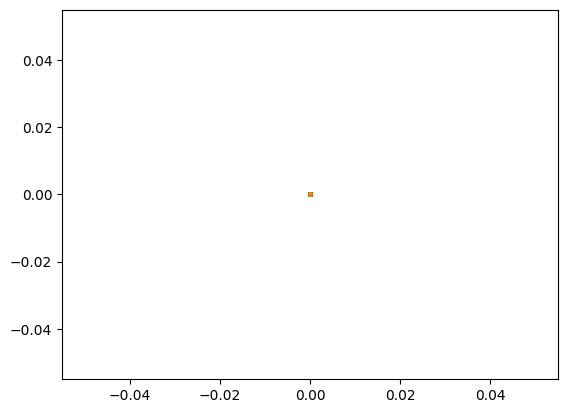

In [61]:
plt.scatter(u, v, s=5, alpha=0.2)
plt.scatter(projections_vline[:, 0], projections_vline[:, 1], s=5, alpha=0.3)

In [62]:
odist_vline = np.abs(X - projections_vline[:u.size])
s_v = 0
for r in range(X.shape[0]):
    s += np.sqrt(odist_vline[r, 0]**2 + odist_vline[r, 1]**2)

NameError: name 's' is not defined

In [ ]:
# hline and vline distances
hline = np.array([1., 0.])
vline = np.array([0., 1.])

projections_h_pre = (X @ hline)
projections_v_pre = (X @ vline)

In [ ]:
projections_h = np.zeros((u.size, 2))
projections_h[:, 0] = projections_h_pre * hline[0]

projections_v = np.zeros((u.size, 2))
projections_v[:, 1] = projections_v_pre * vline[1]

In [ ]:
plt.scatter(u, v, s=5, alpha=0.2)
plt.scatter(projections_v[:, 0], projections_v[:, 1], s=5, alpha=0.3)
plt.scatter(projections_h[:, 0], projections_h[:, 1], s=5, alpha=0.3)

In [ ]:
odists_h = np.abs(X - projections_h)
s_h = 0
for r in range(X.shape[0]):
    s_h += np.sqrt(odists_h[r, 0]**2 + odists_h[r, 1]**2)
dists_h[j] = s_h

odists_v = np.abs(X - projections_v)
s_v = 0
for r in range(X.shape[0]):
    s_v += np.sqrt(odists_v[r, 0]**2 + odists_v[r, 1]**2)
dists_v[j] = s_v

np.float64(2189.5474219250027)

In [147]:
import pygfx

In [148]:
pygfx.__version__

'0.5.0'

In [149]:
import imgui_bundle

In [150]:
imgui_bundle.__version__

'1.5.2'

In [63]:
from numba import guvectorize, float64, int64, float32, prange, njit

In [64]:
dist_cov = np.zeros((Y.shape[0], Y.shape[0]), dtype=np.float32)

In [65]:
%%time
for i in tqdm(range(Y.shape[0])):
    projections = np.zeros((*Y.shape, 2))
    output_matrix = np.zeros((Y.shape[0],))
    output_h = np.zeros((Y.shape[0],))
    output_v = np.zeros((Y.shape[0],))
    get_distances(
        i,
        Y,
        projections,
        output_matrix,
        output_h,
        output_v,
    )
    dist_cov[i] = output_matrix

100%|███████████████████████████████████████████████████████████████████████████████████| 2049/2049 [00:52<00:00, 39.24it/s]

CPU times: user 11min 46s, sys: 49.8 s, total: 12min 36s
Wall time: 52.2 s


In [154]:
@njit(parallel=True)
def distance_matrix(Y, projections, dist_cov):
    for i in prange(Y.shape[0]):
        output_matrix = np.zeros((Y.shape[0],))
        for j in range(Y.shape[0]):
            u = Y[i]
            v = Y[j]
    
            high_val_ixs = (u > np.percentile(u, 95)) | (v > np.percentile(v, 95))
    
            u = u[high_val_ixs]
            v = v[high_val_ixs]

            X = np.zeros((u.size, 2))
            X[:, 0] = u
            X[:, 1] = v
    
            U, S, Vt = np.linalg.svd(X, full_matrices=False)
    
            projections_pre = (X @ Vt[0, :])
                
            projections[i, j, :u.size, 0] = projections_pre * Vt[0, :][0]
            projections[i, j, :u.size, 1] = projections_pre * Vt[0, :][1]
    
            orthogonal_distances = np.abs(X - projections[i, j, :u.size])  # Euclidean distances
            s = 0
            for r in range(X.shape[0]):
                s += np.sqrt(orthogonal_distances[r, 0]**2 + orthogonal_distances[r, 1]**2)
            output_matrix[j] = s**2
                
        dist_cov[i] = output_matrix

In [335]:
n_pixels, t = Y.shape
projections = np.zeros((n_pixels, n_pixels, t, 2))

MemoryError: Unable to allocate 125. GiB for an array with shape (2049, 2049, 2000, 2) and data type float64

In [319]:
%%time
distance_matrix(Y, projections, dist_cov)

CPU times: user 3min 37s, sys: 453 ms, total: 3min 37s
Wall time: 15 s


In [66]:
dist_cov.shape

(2049, 2049)

In [67]:
dist_cov

array([[4.7250869e-14, 7.4062332e+01, 2.8894073e+02, ..., 2.5003479e+02,
        2.6002936e+02, 2.7691080e+02],
       [7.4062332e+01, 3.8055066e-14, 2.8829486e+02, ..., 2.4488438e+02,
        2.6764648e+02, 2.9332565e+02],
       [2.8894073e+02, 2.8829486e+02, 5.9663517e-14, ..., 2.3195848e+02,
        2.6720801e+02, 2.5582268e+02],
       ...,
       [2.5003479e+02, 2.4488438e+02, 2.3195848e+02, ..., 2.8973551e-14,
        2.6035406e+02, 2.6987894e+02],
       [2.6002936e+02, 2.6764648e+02, 2.6720801e+02, ..., 2.6035406e+02,
        3.1057391e-14, 7.7468727e+01],
       [2.7691080e+02, 2.9332565e+02, 2.5582268e+02, ..., 2.6987894e+02,
        7.7468727e+01, 5.9977529e-14]], dtype=float32)

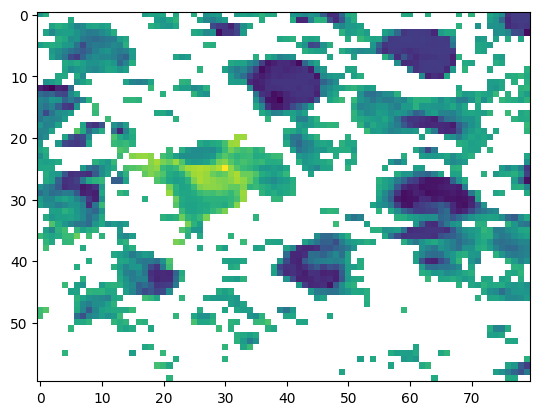

In [96]:
plt.imshow(unvec.transform(dist_cov[1009]), cmap="viridis_r")
plt.show()

In [97]:
dist_cov.min(), dist_cov.max()

(np.float32(2.4716608e-14), np.float32(1773.2864))

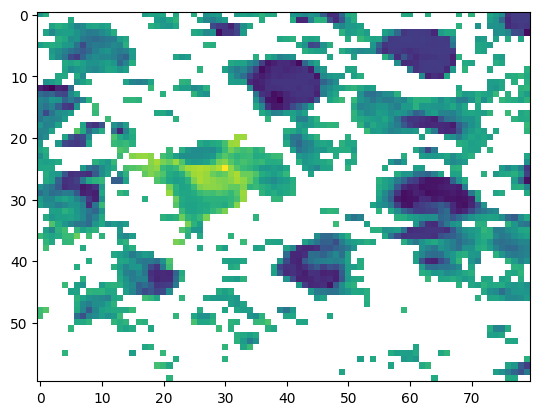

In [98]:
affinity = dist_cov.copy()
affinity -= affinity.max()
affinity = np.abs(affinity)

plt.imshow(unvec.transform(affinity[1009]))
plt.show()

In [99]:
affinity.min(), affinity.max()

(np.float32(0.0), np.float32(1773.2864))

In [100]:
from sklearn.cluster import SpectralClustering

In [137]:
n_clusters = 15
sc = SpectralClustering(n_clusters=n_clusters, affinity="precomputed")

In [138]:
labels = sc.fit_predict(affinity)

In [139]:
labels.shape

(2049,)

In [140]:
labels

array([7, 7, 7, ..., 7, 7, 7], dtype=int32)

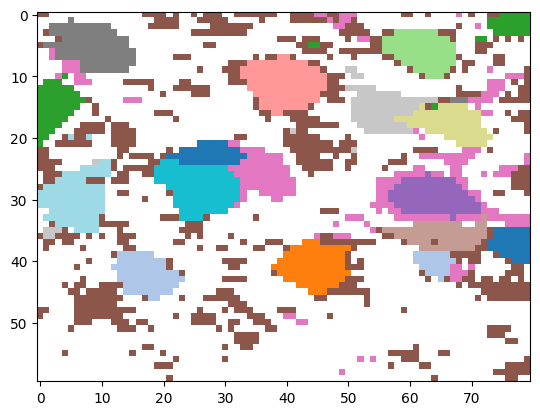

In [141]:
plt.imshow(unvec.transform(labels.astype(np.float32)), cmap="tab20")
plt.show()

In [143]:
labels

array([7, 7, 7, ..., 7, 7, 7], dtype=int32)

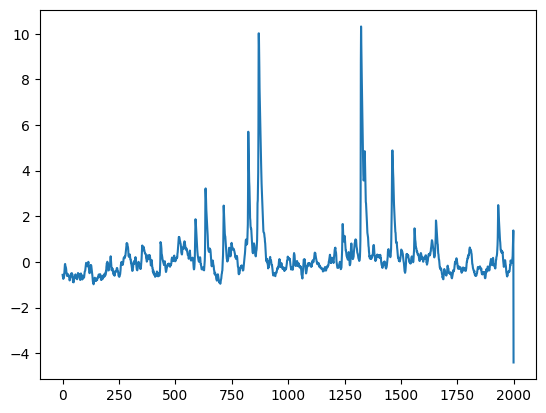

In [151]:
plt.plot(Y[labels == 2].mean(axis=0))

In [152]:
soft_labels = np.zeros((Y.shape[0], n_clusters))
soft_labels.shape

(2049, 15)

In [154]:
for n in tqdm(range(n_clusters)):
    centroid = Y[labels == n].mean(axis=0)

    # compare every pixel to this centroid
    for i in range(Y.shape[0]):
        u = centroid
        v = Y[i]

        high_val_ixs = (u > np.percentile(u, 95)) | (v > np.percentile(v, 95))

        u = u[high_val_ixs]
        v = v[high_val_ixs]

        X = np.zeros((u.size, 2))
        X[:, 0] = u
        X[:, 1] = v

        U, S, Vt = np.linalg.svd(X, full_matrices=False)
        v1 = Vt[0, :]

        projections = (X @ v1)[:, None] * v1

        orthogonal_distances = np.abs(X - projections)  # Euclidean distances
        s = 0
        for r in range(X.shape[0]):
            s += np.sqrt(orthogonal_distances[r, 0]**2 + orthogonal_distances[r, 1]**2)

        soft_labels[i, n] = s

100%|███████████████████████████████████████████████████████████████████████████████████████| 15/15 [00:08<00:00,  1.79it/s]


In [185]:
soft_labels.min(), soft_labels.max()

(np.float64(21.49327651075527), np.float64(970.7104484354772))

In [186]:
soft_labels -= soft_labels.max()
soft_labels = np.abs(soft_labels)

In [187]:
unvec.transform(soft_labels).shape

(15, 60, 80)

RFBOutputContext()

JupyterWgpuCanvas()
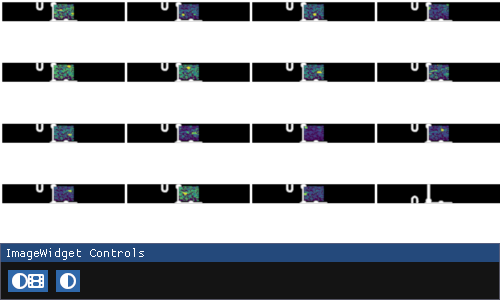

In [188]:
fpl.ImageWidget([l for l in unvec.transform(soft_labels)], cmap="viridis", histogram_widget=False).show()

In [ ]:
3